# Prototype 1 — xLAM Function-Calling: EDA, Cleaning & Splits
**Part 1 (EDA):** explore `Salesforce/xlam-function-calling-60k`: quality, call/tool distributions, label validity, token lengths.
**Part 2 (Cleaning):** turn the findings into a clean, deduplicated, leakage-free dataset with SFT / DPO / test splits.

All helper functions are defined **once** in Part 1 and reused in Part 2.

## Setup

In [1]:
import os
import json
import hashlib
from collections import Counter
from pathlib import Path
from typing import Sized, cast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import notebook_login

## Load the dataset
Uses `HF_TOKEN` from the environment if set, otherwise prompts for login (the dataset is gated).

In [2]:
token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGINGFACE_TOKEN")
if not token:
    notebook_login()

dataset = load_dataset(
    "Salesforce/xlam-function-calling-60k",
    split="train",
    token=token or True,
)

print(dataset)
print(f"Number of examples: {len(cast(Sized, dataset)):,}")

Dataset({
    features: ['id', 'query', 'answers', 'tools'],
    num_rows: 60000
})
Number of examples: 60,000


## Save a raw copy
Create the project data folders and dump the untouched dataset to JSONL so later stages don't depend on the Hub.

In [3]:
for folder in [
    "data/raw",
    "data/processed",
    "data/reports",
    "data/splits"
]:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Directory structure created.")

Directory structure created.


In [4]:
raw_path = "data/raw/xlam_function_calling_60k.jsonl"

dataset.to_json(
    raw_path,
    orient="records",
    lines=True,
    force_ascii=False
)

print(f"Raw dataset saved to: {raw_path}")

Creating json from Arrow format:   0%|          | 0/60 [00:00<?, ?ba/s]

Raw dataset saved to: data/raw/xlam_function_calling_60k.jsonl


## Look at one example
`tools` and `answers` are stored as JSON **strings**, so they need `json.loads` before use.

In [5]:
print("Columns:", dataset.column_names)

sample = dataset[0]
print("\nQUERY\n", sample["query"])
print("\nTOOLS\n", json.dumps(json.loads(sample["tools"]), indent=2))
print("\nANSWERS\n", json.dumps(json.loads(sample["answers"]), indent=2))

Columns: ['id', 'query', 'answers', 'tools']

QUERY
 Where can I find live giveaways for beta access and games?

TOOLS
 [
  {
    "name": "live_giveaways_by_type",
    "description": "Retrieve live giveaways from the GamerPower API based on the specified type.",
    "parameters": {
      "type": {
        "description": "The type of giveaways to retrieve (e.g., game, loot, beta).",
        "type": "str",
        "default": "game"
      }
    }
  }
]

ANSWERS
 [
  {
    "name": "live_giveaways_by_type",
    "arguments": {
      "type": "beta"
    }
  },
  {
    "name": "live_giveaways_by_type",
    "arguments": {
      "type": "game"
    }
  }
]


## Build a per-example profile
One row per example with query length, number of available tools, number of calls in the answer, and whether the JSON parses.

In [ ]:
def parse_json_field(value):
    """Parse a JSON string safely. Returns the parsed object, or None if invalid."""
    if isinstance(value, (dict, list)):
        return value
    if not isinstance(value, str):
        return None
    try:
        return json.loads(value)
    except (json.JSONDecodeError, TypeError):
        return None

In [7]:
records = []

for idx, row in enumerate(dataset):

    tools = parse_json_field(row["tools"])
    answers = parse_json_field(row["answers"])

    records.append({
        "index": idx,
        "query": row["query"],
        "query_length_chars": len(row["query"]) if isinstance(row["query"], str) else None,
        "num_tools": len(tools) if isinstance(tools, list) else None,
        "num_calls": len(answers) if isinstance(answers, list) else None,
        "tools_valid_json": tools is not None,
        "answers_valid_json": answers is not None,
    })

profile_df = pd.DataFrame(records)

profile_df.head()

,index,query,query_length_chars,num_tools,num_calls,tools_valid_json,answers_valid_json
0,0,Where can I find live giveaways for beta acces...,58,1,2,True,True
1,1,I need to understand the details of the Ethere...,132,2,1,True,True
2,2,What is the T3MA for 'ETH/BTC' using a 1h inte...,75,2,1,True,True
3,3,List titles originally aired on networks '1' a...,118,2,1,True,True
4,4,Fetch the competitor standings for the recentl...,70,1,1,True,True


## Data quality checks

In [8]:
print("Total records:", len(profile_df))

print("\nInvalid tool JSON:")
print((~profile_df["tools_valid_json"]).sum())

print("\nInvalid answer JSON:")
print((~profile_df["answers_valid_json"]).sum())

print("\nMissing queries:")
print(profile_df["query"].isna().sum())

print("\nEmpty queries:")
print((profile_df["query"].fillna("").str.strip() == "").sum())

Total records: 60000

Invalid tool JSON:
0

Invalid answer JSON:
0

Missing queries:
0

Empty queries:
0


## Query length

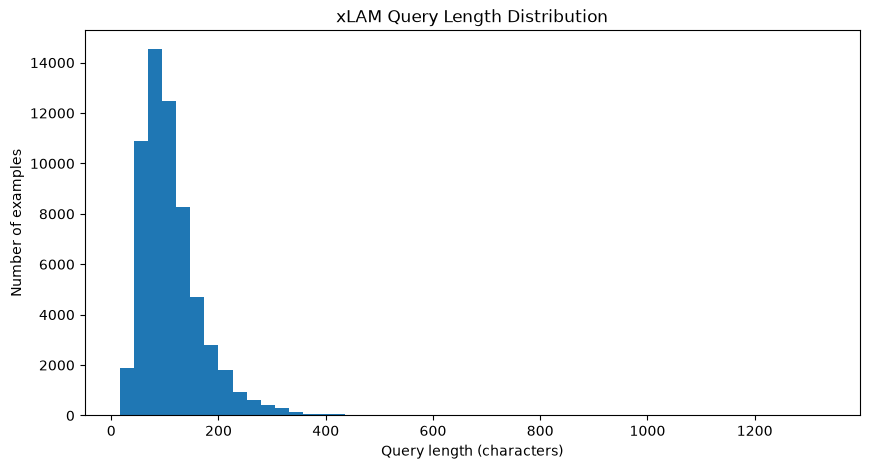

In [9]:
plt.figure(figsize=(10, 5))

plt.hist(
    profile_df["query_length_chars"].dropna(),
    bins=50
)

plt.xlabel("Query length (characters)")
plt.ylabel("Number of examples")
plt.title("xLAM Query Length Distribution")

plt.show()

In [10]:
print("Shortest queries:")
display(
    profile_df
    .sort_values("query_length_chars")
    [["index", "query", "query_length_chars"]]
    .head(10)
)

print("\nLongest queries:")
display(
    profile_df
    .sort_values("query_length_chars", ascending=False)
    [["index", "query", "query_length_chars"]]
    .head(10)
)

Shortest queries:


,index,query,query_length_chars
25263,25263,Can Pikachu run?,16
37158,37158,Generate 10 UUIDs.,18
2003,2003,Generate 10 UUIDs.,18
116,116,Is 27 a power of 3?,19
12279,12279,Is 27 a power of 3?,19
13208,13208,Is 64 a power of 2?,19
20689,20689,Is 64 a power of 2?,19
12023,12023,Roll a 6-sided die.,19
49647,49647,Is 81 a power of 3?,19
3596,3596,Is 64 a power of 2?,19



Longest queries:


,index,query,query_length_chars
57179,57179,Check if the following three Sudoku boards are...,1330
44334,44334,A Sudoku enthusiast has two puzzles to solve a...,975
8400,8400,Can you validate two Sudoku boards? The first ...,935
44400,44400,Check the validity of the following two Sudoku...,921
56714,56714,Check the validity of the following Sudoku boa...,917
49757,49757,Check if the following two Sudoku boards are v...,903
19324,19324,Verify if these two Sudoku boards are valid: [...,897
38659,38659,Suppose you are a financial analyst and you ha...,709
53220,53220,How can I split the following text into chunks...,619
51911,51911,How can I split the following text into chunks...,605


## How many calls per answer?
Multi-call examples (parallel function calling) are what make this dataset harder than single-call ones.

In [11]:
call_stats = pd.DataFrame({
    "count": profile_df["num_calls"].value_counts().sort_index(),
    "percent": (profile_df["num_calls"].value_counts(normalize=True).sort_index() * 100).round(2),
})

call_stats

,count,percent
num_calls,,
1,28461,47.44
2,25422,42.37
3,4697,7.83
4,1056,1.76
5,187,0.31
6,94,0.16
7,20,0.03
8,12,0.02
9,12,0.02


## How many tools are offered per example?
The model has to pick the right tool(s) out of this list, so more tools = more distractors.

In [12]:
display(profile_df["num_tools"].describe())
display(profile_df["num_tools"].value_counts().sort_index())

count    60000.00000
mean         2.81450
std          1.60361
min          1.00000
25%          1.00000
50%          3.00000
75%          4.00000
max          8.00000
Name: num_tools, dtype: float64

num_tools
1    15410
2    12726
3    12655
4    13078
5     2427
6     1464
7     1108
8     1132
Name: count, dtype: int64

## Tool names and argument types
One pass over the dataset to collect tool names and parameter types.

xLAM has no `required` key, so we infer it:
- type string contains `optional` (e.g. `"str, optional"`) → optional
- otherwise, if it has a non-empty `default` (e.g. `"type": "str", "default": "game"`) → effectively optional, the model doesn't *have* to pass it
- otherwise → **required**

In [13]:
def is_required(param_info):
    """Required = not marked optional AND no non-empty default."""
    if not isinstance(param_info, dict):
        return False
    if "optional" in str(param_info.get("type", "")):
        return False
    return param_info.get("default") in (None, "")

In [14]:
tool_names = []
argument_types = Counter()
required_count = 0
optional_count = 0

for row in dataset:
    tools = parse_json_field(row["tools"])
    if not isinstance(tools, list):
        continue

    for tool in tools:
        if not isinstance(tool, dict):
            continue

        if "name" in tool:
            tool_names.append(tool["name"])

        parameters = tool.get("parameters", {})
        if not isinstance(parameters, dict):
            continue

        for param_info in parameters.values():
            param_type = param_info.get("type", "unknown") if isinstance(param_info, dict) else "unknown"
            argument_types[param_type] += 1

            if is_required(param_info):
                required_count += 1
            else:
                optional_count += 1

print(f"Total tool definitions: {len(tool_names):,}")
print(f"Unique tool names:      {len(set(tool_names)):,}")
print(f"\nRequired parameters: {required_count:,}")
print(f"Optional parameters: {optional_count:,}")

print("\nMost used tools:")
for name, count in Counter(tool_names).most_common(15):
    print(f"  {name:35} {count:,}")

print("\nArgument types:")
for arg_type, count in argument_types.most_common():
    print(f"  {arg_type:30} {count:,}")

Total tool definitions: 168,870
Unique tool names:      3,605

Required parameters: 108,208
Optional parameters: 254,274

Most used tools:
  search                              2,187
  sort_numbers                        763
  cell_density                        703
  calculate_standard_deviation        689
  find_pairs_with_sum                 668
  get_ip_zipcode                      654
  is_perfect_square                   639
  bacterial_growth                    634
  find_n_largest_numbers              624
  project_investment_growth           621
  final_velocity                      612
  calculate_investment_return         605
  std_deviation                       603
  is_leap_year                        595
  numerical_derivative                593

Argument types:
  str                            130,067
  str, optional                  70,623
  int                            67,509
  int, optional                  32,701
  float                          21,818
  List[int]

## Exact duplicates
Hash `query + tools + answers` (with JSON canonicalised so key order doesn't matter) to find exact duplicate records.

In [ ]:
def canonical_json(value):
    """Stable JSON string (sorted keys, no spaces) so key order doesn't change the hash."""
    parsed = parse_json_field(value) if isinstance(value, str) else value
    if parsed is None:
        return str(value)
    return json.dumps(parsed, ensure_ascii=False, sort_keys=True, separators=(",", ":"))


def record_hash(record):
    """Works on raw rows (JSON strings) and on parsed records alike."""
    content = record["query"] + canonical_json(record["tools"]) + canonical_json(record["answers"])
    return hashlib.sha256(content.encode("utf-8")).hexdigest()

In [16]:
hashes = [
    record_hash(row)
    for row in dataset
]

hash_counts = Counter(hashes)

duplicate_records = sum(
    count - 1
    for count in hash_counts.values()
    if count > 1
)

print("Total records:", len(dataset))
print("Unique records:", len(hash_counts))
print("Exact duplicate records:", duplicate_records)

Total records: 60000
Unique records: 59625
Exact duplicate records: 375


In [17]:
# keep the hash on the profile so we can drop duplicates later
profile_df["record_hash"] = hashes
profile_df["is_exact_dup"] = profile_df["record_hash"].duplicated()

## Query-level duplicates
Exact-dup checks miss cases where the **same question** appears with a different tool list or answer.
If those variants end up in both train and test, eval scores get inflated (leakage).
We won't drop them (the tool lists differ, so they're real examples), but we'll make sure all variants of a query land in the **same split**.

In [ ]:
def normalize_query(query):
    """Lowercase + collapse whitespace, so trivial variants count as the same question."""
    if not isinstance(query, str):
        return ""
    return " ".join(query.lower().split())


profile_df["query_norm"] = profile_df["query"].map(normalize_query)

query_counts = profile_df["query_norm"].value_counts()
repeated = query_counts[query_counts > 1]

print(f"Unique queries:                          {len(query_counts):,}")
print(f"Queries appearing more than once:        {len(repeated):,}")
print(f"Examples sharing a query with another:   {repeated.sum():,}")

repeated.head(10)

## Do the answers actually match the tools?
For function calling, the labels *are* the task, so we check every call in every answer:

| Issue | Meaning |
|---|---|
| `unknown_tool` | answer calls a function that isn't in the example's `tools` list |
| `unknown_argument` | passes an argument the function doesn't define |
| `missing_required` | skips a required parameter (using `is_required` from above) |
| `type_mismatch` | value doesn't match the declared type, e.g. `"5"` for an `int` |

The first three are hard errors. `type_mismatch` is softer (some APIs accept `"5"` for an int), so we report it but don't filter on it.

`validate_tool_calls` is defined here once and reused by the cleaning pipeline in Part 2.

In [ ]:
TYPE_CHECKS = {
    "str":   lambda v: isinstance(v, str),
    "int":   lambda v: isinstance(v, int) and not isinstance(v, bool),
    "float": lambda v: isinstance(v, (int, float)) and not isinstance(v, bool),
    "bool":  lambda v: isinstance(v, bool),
    "list":  lambda v: isinstance(v, list),
    "dict":  lambda v: isinstance(v, dict),
}


def base_type(type_str):
    """'str, optional' -> 'str', 'List[int]' / 'Tuple[..]' / 'set' -> 'list'. Unknown -> None (skip)."""
    if type_str is None:
        return None
    t = str(type_str).split(",")[0].strip().lower()
    if t.startswith(("list", "tuple", "set")):
        return "list"   # JSON has no tuple/set, they come through as lists
    if t.startswith("dict"):
        return "dict"
    return t if t in TYPE_CHECKS else None   # Callable, Union, ... -> can't check


def validate_tool_calls(tools, answers):
    """Check every call in `answers` against the `tools` it was given. Returns a list of issue labels."""
    if not isinstance(tools, list):
        return ["invalid_tools"]
    if not isinstance(answers, list):
        return ["invalid_answers"]

    issues = []
    tool_map = {
        tool["name"]: tool.get("parameters") or {}
        for tool in tools
        if isinstance(tool, dict) and isinstance(tool.get("name"), str)
    }

    for call in answers:
        if not isinstance(call, dict):
            issues.append("invalid_call")
            continue

        if call.get("name") not in tool_map:
            issues.append("unknown_tool")
            continue

        params = tool_map[call["name"]]
        arguments = call.get("arguments", {})
        if not isinstance(arguments, dict):
            issues.append("invalid_arguments")
            continue

        # supplied arguments must exist and roughly match their declared type
        for arg_name, value in arguments.items():
            if arg_name not in params:
                issues.append("unknown_argument")
                continue
            param_info = params[arg_name]
            if not isinstance(param_info, dict):
                continue
            expected = base_type(param_info.get("type"))
            if expected and not TYPE_CHECKS[expected](value):
                issues.append("type_mismatch")

        # required parameters must be passed
        for param_name, param_info in params.items():
            if is_required(param_info) and param_name not in arguments:
                issues.append("missing_required")

    return issues

In [ ]:
# Issue labels used everywhere below (EDA and cleaning)
HARD_ISSUES = {
    # structural
    "invalid_query", "invalid_tools", "empty_tools", "invalid_answers", "empty_answers",
    # tool schema
    "tool_not_object", "tool_missing_name", "invalid_parameters", "conflicting_tool_definitions",
    # call vs tools
    "invalid_call", "unknown_tool", "invalid_arguments", "unknown_argument", "missing_required",
}
SOFT_ISSUES = {"type_mismatch"}

profile_df["issues"] = [
    validate_tool_calls(parse_json_field(row["tools"]), parse_json_field(row["answers"]))
    for row in dataset
]
profile_df["has_hard_issue"] = profile_df["issues"].apply(lambda xs: bool(HARD_ISSUES & set(xs)))

# count each issue type once per example
issue_counts = Counter(issue for xs in profile_df["issues"] for issue in set(xs))

print("Examples with each issue:")
for issue, count in issue_counts.most_common():
    print(f"  {issue:20} {count:6,}  ({count / len(profile_df):.2%})")

print(f"\nExamples with a hard call issue: {profile_df['has_hard_issue'].sum():,}")

In [21]:
# eyeball a few broken examples to make sure the checker isn't wrong
for idx in profile_df.loc[profile_df["has_hard_issue"], "index"].head(3):
    row = dataset[int(idx)]
    print("ISSUES :", profile_df.loc[idx, "issues"])
    print("QUERY  :", row["query"])
    print("TOOLS  :", row["tools"][:400])
    print("ANSWER :", row["answers"])
    print("-" * 80)

ISSUES : ['missing_required', 'missing_required']
QUERY  : What is the electric field intensity at 3 meters from a 2 Coulomb charge, and at 4 meters from a 3 Coulomb charge?
TOOLS  : [{"name": "calculate_electric_field", "description": "Calculate the electric field produced by a charge at a certain distance.", "parameters": {"charge": {"description": "Charge in coulombs producing the electric field.", "type": "int", "default": 8.854e-12}, "distance": {"description": "Distance from the charge in meters where the field is being measured.", "type": "int", "default": 8.854e-12}, "
ANSWER : [{"name": "calculate_electric_field", "arguments": {"charge": 2, "distance": 3}}, {"name": "calculate_electric_field", "arguments": {"charge": 3, "distance": 4}}]
--------------------------------------------------------------------------------
ISSUES : ['missing_required']
QUERY  : Calculate the electric field produced by a charge of 1 Coulomb at a distance of 1 meter.
TOOLS  : [{"name": "calculate_elect

## What kind of multi-call examples are there?
"2 calls" can mean two very different skills:
- **parallel_same_tool**: same function called several times (e.g. weather for 3 cities)
- **multi_distinct_tools**: different functions in one answer (pick several tools)
- **mixed**: a bit of both

Good to know, since a model can be strong at one and weak at the other. Worth tracking separately in eval.

In [22]:
def call_pattern(answers):
    if not isinstance(answers, list) or len(answers) == 0:
        return "no_call"
    if len(answers) == 1:
        return "single"
    names = [c.get("name") for c in answers if isinstance(c, dict)]
    if len(set(names)) == 1:
        return "parallel_same_tool"
    if len(set(names)) == len(names):
        return "multi_distinct_tools"
    return "mixed"


profile_df["call_pattern"] = [call_pattern(parse_json_field(row["answers"])) for row in dataset]

pd.DataFrame({
    "count": profile_df["call_pattern"].value_counts(),
    "percent": (profile_df["call_pattern"].value_counts(normalize=True) * 100).round(2),
})

,count,percent
call_pattern,,
single,28461,47.44
multi_distinct_tools,18972,31.62
parallel_same_tool,11091,18.48
mixed,1476,2.46


In [23]:
# the biggest outlier: is this a real example or junk?
outlier_idx = int(profile_df["num_calls"].idxmax())
outlier = dataset[outlier_idx]

print(f"Index {outlier_idx} | {profile_df.loc[outlier_idx, 'num_calls']} calls")
print("QUERY:", outlier["query"])
print("FIRST 3 CALLS:", json.dumps(json.loads(outlier["answers"])[:3], indent=1))

Index 40513 | 52 calls
QUERY: Get tide information for station 8418150 on every Monday in 2022.
FIRST 3 CALLS: [
 {
  "name": "get_tides_for_a_station",
  "arguments": {
   "is_id": "8418150",
   "date": "20220103"
  }
 },
 {
  "name": "get_tides_for_a_station",
  "arguments": {
   "is_id": "8418150",
   "date": "20220110"
  }
 },
 {
  "name": "get_tides_for_a_station",
  "arguments": {
   "is_id": "8418150",
   "date": "20220117"
  }
 }
]


## The gap: no "don't call a tool" examples
Every example has at least one call (`no_call` doesn't show up above).
A model trained only on this learns to **always** call a tool, even for "hi, how are you?".
Not fixable inside xLAM. Plan to mix in irrelevance examples (query + tools where none apply → plain text reply) later. They also make great DPO pairs (rejected = calling a tool anyway).

## Token lengths (what actually matters for training)
Character counts on the query alone are misleading. The model sees the **full formatted example**: tool schemas + query + answer, wrapped in the chat template.
This sets `max_seq_length`, which drives memory use, speed and how many examples get truncated.

👉 Change `TOKENIZER_NAME` to the base model you'll fine-tune. Lengths differ between tokenizers.

In [ ]:
from transformers import AutoTokenizer

TOKENIZER_NAME = "Qwen/Qwen2.5-0.5B-Instruct"   # <- swap for your base model
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)


def format_example(query, tools, answers):
    """Simple training format: tools in the system prompt, answer as JSON. Takes parsed tools/answers."""
    messages = [
        {"role": "system", "content": "You have access to these tools:\n" + json.dumps(tools, ensure_ascii=False)},
        {"role": "user", "content": query},
        {"role": "assistant", "content": json.dumps(answers, ensure_ascii=False)},
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False)


def count_tokens(texts):
    return [len(ids) for ids in tokenizer(texts, add_special_tokens=False)["input_ids"]]


parsed_rows = [
    (row["query"], parse_json_field(row["tools"]), parse_json_field(row["answers"]))
    for row in dataset
]
profile_df["total_tokens"] = count_tokens([format_example(q, t, a) for q, t, a in parsed_rows])
profile_df["tool_tokens"] = count_tokens([json.dumps(t, ensure_ascii=False) for _, t, _ in parsed_rows])

print(profile_df["total_tokens"].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(0))
print(f"\nShare of tokens spent on tool schemas: {profile_df['tool_tokens'].sum() / profile_df['total_tokens'].sum():.1%}")

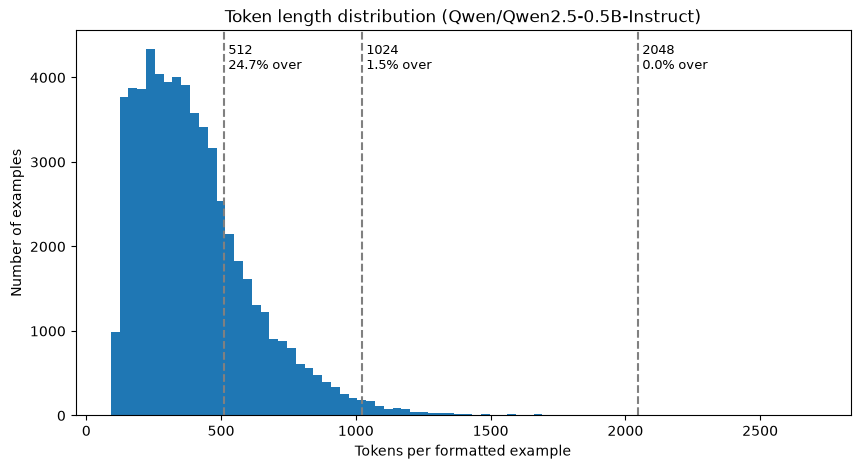

In [25]:
plt.figure(figsize=(10, 5))
plt.hist(profile_df["total_tokens"], bins=80)

for limit in [512, 1024, 2048]:
    over = (profile_df["total_tokens"] > limit).mean()
    plt.axvline(limit, linestyle="--", color="gray")
    plt.text(limit, plt.ylim()[1] * 0.9, f" {limit}\n {over:.1%} over", fontsize=9)

plt.xlabel("Tokens per formatted example")
plt.ylabel("Number of examples")
plt.title(f"Token length distribution ({TOKENIZER_NAME})")
plt.show()

## Candidate hard examples
A rough complexity score: more tools, more calls (weighted ×2) and longer queries rank higher. Useful for picking eval examples later.

In [26]:
profile_df["complexity_score"] = (
    profile_df["num_tools"].fillna(0)
    + profile_df["num_calls"].fillna(0) * 2
    + profile_df["query_length_chars"].fillna(0) / 500
)

candidate_difficult = profile_df.sort_values("complexity_score", ascending=False).head(20)

display(candidate_difficult[
    ["index", "num_tools", "num_calls", "query_length_chars", "complexity_score", "query"]
])

,index,num_tools,num_calls,query_length_chars,complexity_score,query
40513,40513,1,52,65,105.130,Get tide information for station 8418150 on ev...
12549,12549,5,30,54,65.108,Get rugby fixtures for the entire month of Apr...
50260,50260,1,26,97,53.194,What were the railway periods for the UTC date...
6420,6420,4,23,70,50.140,Retrieve pit stop data for all rounds of the F...
59732,59732,1,24,77,49.154,Could you provide me with the earnings data fo...
58947,58947,2,20,93,42.186,Get earnings information for the 10 largest co...
59801,59801,1,20,71,41.142,What is the smallest number that is the sum of...
53185,53185,2,19,79,40.158,Find the longest palindromic substring in the ...
36224,36224,4,14,127,32.254,What are the trading signals for BTC on Binanc...
44674,44674,2,14,221,30.442,Retrieve the daily financial reports for the f...


## Summary

In [27]:
summary = {
    "total_examples": len(dataset),
    "unique_exact_records": len(hash_counts),
    "exact_duplicate_records": duplicate_records,
    "invalid_tool_json": int((~profile_df["tools_valid_json"]).sum()),
    "invalid_answer_json": int((~profile_df["answers_valid_json"]).sum()),
    "missing_queries": int(profile_df["query"].isna().sum()),
    "avg_query_length": profile_df["query_length_chars"].mean(),
    "median_query_length": profile_df["query_length_chars"].median(),
    "max_query_length": profile_df["query_length_chars"].max(),
    "avg_available_tools": profile_df["num_tools"].mean(),
    "avg_tool_calls": profile_df["num_calls"].mean(),
    "max_tool_calls": profile_df["num_calls"].max(),
}

summary_df = pd.DataFrame(
    summary.items(),
    columns=["metric", "value"]
)

display(summary_df)

,metric,value
0,total_examples,60000.00000
1,unique_exact_records,59625.00000
2,exact_duplicate_records,375.00000
3,invalid_tool_json,0.00000
4,invalid_answer_json,0.00000
5,missing_queries,0.00000
6,avg_query_length,111.89315
7,median_query_length,100.00000
8,max_query_length,1330.00000
9,avg_available_tools,2.81450


### Key findings
- **60,000** examples, all JSON parses cleanly, no missing/empty queries.
- **375 exact duplicates** (59,625 unique). Another **2,863** examples share a query (1,009 repeated queries, e.g. "Is the year 2000 a leap year?" ×27), so split by query, not by row.
- Labels are clean: no unknown tools or arguments. **558 (0.9%)** skip a required parameter, mostly a schema bug in `calculate_electric_field` (`permitivity` has no default, but answers never pass it). These are dropped in Part 2.
- ~2% have soft type mismatches (e.g. `"5"` for an `int`). Kept, but worth watching.
- Calls: 47% single, 32% distinct tools, 18% same tool in parallel, 2.5% mixed. The 52-call outlier is legit ("tides every Monday in 2022").
- 1–8 tools per example (mean ≈ 2.8), **3,605** unique tool names. Tool schemas are roughly **¾ of all tokens**, so they drive sequence length.
- 259 examples list two *different* tools under the same name (e.g. `facilities_lookup` for Cameroon and for Tanzania). That's ambiguous, so they're dropped too.
- **Gap:** no "no tool needed" examples. The model will over-call tools unless we add some.

## Save the EDA report

In [ ]:
report_cols = [
    "index", "query_length_chars", "num_tools", "num_calls", "call_pattern",
    "total_tokens", "tool_tokens", "is_exact_dup", "has_hard_issue", "complexity_score",
]
profile_df[report_cols].to_csv("data/reports/profile.csv", index=False)

eda_report = {
    **{k: (v.item() if hasattr(v, "item") else v) for k, v in summary.items()},
    "tokenizer": TOKENIZER_NAME,
    "issue_counts_per_example": dict(issue_counts),
    "call_patterns": profile_df["call_pattern"].value_counts().to_dict(),
    "token_percentiles": profile_df["total_tokens"].quantile([0.5, 0.9, 0.95, 0.99]).to_dict(),
}

with open("data/reports/eda_summary.json", "w", encoding="utf-8") as f:
    json.dump(eda_report, f, indent=2, default=str)

print("Saved data/reports/profile.csv and data/reports/eda_summary.json")

# Part 2 — Cleaning & splits
The pipeline, in order (each step only sees what survived the previous one):

```
raw 60k → normalize → repair tool lists → validate (drop hard issues) → exact dedup
        → length filter → grouped + stratified split → save → verify → evidence
```
Splits are built **from the cleaned data**, so everything downstream (SFT, DPO, eval) reads the same clean records.

In [ ]:
RAW_PATH = Path("data/raw/xlam_function_calling_60k.jsonl")
CLEAN_PATH = Path("data/processed/xlam_clean.jsonl")
SPLITS_DIR = Path("data/splits")
REPORT_PATH = Path("data/reports/cleaning_report.json")

SEED = 42
LENGTH_COVERAGE = 0.99   # MAX_SEQ_LEN covers this share of clean examples
SPLIT_FRACTIONS = {"test": 0.05, "dpo_pool": 0.15, "sft_val": 0.02, "sft_train": 0.78}

assert RAW_PATH.exists(), f"Raw dataset not found: {RAW_PATH}"
assert abs(sum(SPLIT_FRACTIONS.values()) - 1) < 1e-9, "split fractions must sum to 1"
print(f"Using raw dataset: {RAW_PATH}")

In [ ]:
raw_records = []

with RAW_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            raw_records.append(json.loads(line))

print(f"Loaded {len(raw_records):,} raw records")

## 1. Normalize
Parse `tools` / `answers` from JSON strings into Python objects, collapse whitespace in the query, and **keep `id`** so every clean example can be traced back to the raw data.

In [ ]:
def normalize_record(record):
    """Convert one raw xLAM record into canonical Python structures."""
    query = record.get("query")
    if isinstance(query, str):
        query = " ".join(query.strip().split())

    return {
        "id": record.get("id"),
        "query": query,
        "tools": parse_json_field(record.get("tools")),
        "answers": parse_json_field(record.get("answers")),
    }


normalized_records = [normalize_record(r) for r in raw_records]

assert len({r["id"] for r in normalized_records}) == len(normalized_records), "ids must be unique"
print(f"Normalized records: {len(normalized_records):,}")

## 2. Repair before dropping
Some tool lists contain the same tool twice. If both copies are **identical**, that's harmless, so remove the copy and keep the example.
If two **different** tools share a name, it's ambiguous which one is meant, so the validator flags it as `conflicting_tool_definitions` in the next step.

In [ ]:
def dedupe_identical_tools(tools):
    """Drop exact repeat tool definitions. Returns (tools, n_removed)."""
    if not isinstance(tools, list):
        return tools, 0
    seen, unique = set(), []
    for tool in tools:
        key = canonical_json(tool)
        if key not in seen:
            seen.add(key)
            unique.append(tool)
    return unique, len(tools) - len(unique)


repaired_examples = 0
for record in normalized_records:
    record["tools"], n_removed = dedupe_identical_tools(record["tools"])
    repaired_examples += n_removed > 0

print(f"Examples repaired (identical duplicate tools removed): {repaired_examples:,}")

## 3. Validate
Three layers of checks, every issue labelled as hard (drop) or soft (keep, but report):
- **structural**: query / tools / answers exist and have the right type
- **tool schema**: each tool is an object with a name; no two different tools share a name
- **calls vs tools**: `validate_tool_calls` from Part 1

In [ ]:
def structural_issues(record):
    issues = []

    query = record["query"]
    tools = record["tools"]
    answers = record["answers"]

    if not isinstance(query, str) or not query.strip():
        issues.append("invalid_query")

    if not isinstance(tools, list):
        issues.append("invalid_tools")

    elif len(tools) == 0:
        issues.append("empty_tools")

    if not isinstance(answers, list):
        issues.append("invalid_answers")

    elif len(answers) == 0:
        issues.append("empty_answers")

    return issues

In [ ]:
def validate_tool_schema(tools):
    if not isinstance(tools, list):
        return ["invalid_tools"]

    issues = []
    seen_names = set()

    for tool in tools:
        if not isinstance(tool, dict):
            issues.append("tool_not_object")
            continue

        name = tool.get("name")
        if not isinstance(name, str) or not name.strip():
            issues.append("tool_missing_name")
            continue

        # identical copies were already removed, so a repeated name means different definitions
        if name in seen_names:
            issues.append("conflicting_tool_definitions")
        seen_names.add(name)

        parameters = tool.get("parameters")
        if parameters is not None and not isinstance(parameters, dict):
            issues.append("invalid_parameters")

    return issues

In [ ]:
for record in normalized_records:
    all_issues = set(
        structural_issues(record)
        + validate_tool_schema(record["tools"])
        + validate_tool_calls(record["tools"], record["answers"])
    )
    record["_hard_issues"] = sorted(all_issues & HARD_ISSUES)
    record["_soft_issues"] = sorted(all_issues & SOFT_ISSUES)
    record["_drop_reason"] = "hard_issue" if record["_hard_issues"] else None

# per-example counts (an example with 2 missing params counts once)
example_issue_counts = Counter(
    issue for r in normalized_records for issue in r["_hard_issues"] + r["_soft_issues"]
)

print("Examples with each issue:")
for issue, count in example_issue_counts.most_common():
    kind = "hard" if issue in HARD_ISSUES else "soft"
    print(f"  {issue:30} {count:6,}  ({kind})")

## 4. Exact deduplication
Among the records that passed validation, keep the first copy of each `query + tools + answers` (hashed with `record_hash` from Part 1).

In [ ]:
seen_hashes = set()

for record in normalized_records:
    if record["_drop_reason"]:
        continue
    h = record_hash(record)
    if h in seen_hashes:
        record["_drop_reason"] = "exact_duplicate"
    else:
        seen_hashes.add(h)

print(f"Exact duplicates removed: {sum(r['_drop_reason'] == 'exact_duplicate' for r in normalized_records):,}")

## 5. Length filter
Measure the full formatted example with the real tokenizer (`format_example` from Part 1). `MAX_SEQ_LEN` covers 99% of the remaining examples, rounded up to a multiple of 256.
Longer examples are **dropped, not truncated**, since a cut-off answer is a broken label.

In [ ]:
survivors = [r for r in normalized_records if not r["_drop_reason"]]

token_counts = count_tokens([format_example(r["query"], r["tools"], r["answers"]) for r in survivors])
for record, n in zip(survivors, token_counts):
    record["_tokens"] = n

MAX_SEQ_LEN = int(np.ceil(np.quantile(token_counts, LENGTH_COVERAGE) / 256) * 256)

for record in survivors:
    if record["_tokens"] > MAX_SEQ_LEN:
        record["_drop_reason"] = "too_long"

print(f"MAX_SEQ_LEN = {MAX_SEQ_LEN}")
print(f"Too long:     {sum(r['_drop_reason'] == 'too_long' for r in normalized_records):,}")

In [ ]:
clean_records = [r for r in normalized_records if not r["_drop_reason"]]
drop_reasons = Counter(r["_drop_reason"] for r in normalized_records if r["_drop_reason"])

funnel = [("raw", len(normalized_records))]
remaining = len(normalized_records)
for reason in ["hard_issue", "exact_duplicate", "too_long"]:
    remaining -= drop_reasons[reason]
    funnel.append((f"after dropping {reason}", remaining))

for name, n in funnel:
    print(f"{name:30} {n:7,}")

assert remaining == len(clean_records)

## 6. Grouped + stratified split
- **Group by query**: all variants of the same question land in the same split, so there's no leakage.
- **Stratify by number of calls** (1, 2, 3, 4+): every split keeps the same difficulty mix.
- Queries are **sorted before shuffling** so the split is identical on every run and machine.

In [ ]:
# a query's bucket = its hardest variant
bucket_by_query = {}
for r in clean_records:
    q = normalize_query(r["query"])
    bucket_by_query[q] = max(bucket_by_query.get(q, 0), min(len(r["answers"]), 4))

queries_by_bucket = {}
for q, bucket in bucket_by_query.items():
    queries_by_bucket.setdefault(bucket, []).append(q)

rng = np.random.default_rng(SEED)
split_names = list(SPLIT_FRACTIONS)
query_to_split = {}

for bucket in sorted(queries_by_bucket):
    qs = sorted(queries_by_bucket[bucket])
    qs = [qs[i] for i in rng.permutation(len(qs))]
    start = 0
    for k, name in enumerate(split_names):
        # last split takes the remainder so nothing is lost to rounding
        end = len(qs) if k == len(split_names) - 1 else start + round(SPLIT_FRACTIONS[name] * len(qs))
        for q in qs[start:end]:
            query_to_split[q] = name
        start = end

for r in clean_records:
    r["_split"] = query_to_split[normalize_query(r["query"])]

split_df = pd.DataFrame({
    "split": [r["_split"] for r in clean_records],
    "calls_bucket": [min(len(r["answers"]), 4) for r in clean_records],
})
print(split_df["split"].value_counts()[split_names])
print("\nCalls-bucket mix per split (%) should look about the same in every row:")
display((pd.crosstab(split_df["split"], split_df["calls_bucket"], normalize="index") * 100).round(1))

## 7. Save
Public fields only (`id`, `query`, `tools`, `answers`), with `tools` / `answers` stored as parsed JSON (not strings).

In [ ]:
PUBLIC_FIELDS = ["id", "query", "tools", "answers"]


def write_jsonl(path, records):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps({k: r[k] for k in PUBLIC_FIELDS}, ensure_ascii=False) + "\n")


write_jsonl(CLEAN_PATH, clean_records)
print(f"{'all clean':10} {len(clean_records):7,} -> {CLEAN_PATH}")

for name in split_names:
    split_records = [r for r in clean_records if r["_split"] == name]
    write_jsonl(SPLITS_DIR / f"{name}.jsonl", split_records)
    print(f"{name:10} {len(split_records):7,} -> {SPLITS_DIR / f'{name}.jsonl'}")

## 8. Verify the saved files
Reload **everything** from disk and check it, not just the first few rows.

In [ ]:
def read_jsonl(path):
    with path.open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


reloaded_clean = read_jsonl(CLEAN_PATH)
reloaded_splits = {name: read_jsonl(SPLITS_DIR / f"{name}.jsonl") for name in split_names}

# 1. every record has the right shape and no hard issues
for r in reloaded_clean:
    assert set(r) == set(PUBLIC_FIELDS)
    assert isinstance(r["query"], str) and r["query"]
    assert isinstance(r["tools"], list) and isinstance(r["answers"], list)
    assert not (set(validate_tool_calls(r["tools"], r["answers"])) & HARD_ISSUES)

# 2. splits are a partition of the clean file
split_ids = [r["id"] for recs in reloaded_splits.values() for r in recs]
assert len(split_ids) == len(set(split_ids)), "an id appears in two splits"
assert set(split_ids) == {r["id"] for r in reloaded_clean}, "splits don't match the clean file"

# 3. no query appears in more than one split
query_splits = {}
for name, recs in reloaded_splits.items():
    for r in recs:
        query_splits.setdefault(normalize_query(r["query"]), set()).add(name)
assert max(len(s) for s in query_splits.values()) == 1, "query leakage between splits"

# 4. nothing longer than MAX_SEQ_LEN
assert max(r["_tokens"] for r in clean_records) <= MAX_SEQ_LEN

print(f"All {len(reloaded_clean):,} clean records verified ✅")
print("Splits are a leak-free partition of the clean file ✅")

## 9. Did cleaning help? Evidence without training twice
Cleaning removed only ~3% of examples, so its effect on accuracy would likely be lost in noise. Its real value is **evaluation integrity**, and that can be measured right now:
1. **Leakage:** simulate the lazy approach (random row-level split of the raw data, same test size and seed) and count test examples whose question also appears in train.
2. **Broken yardstick:** count test examples whose label is itself broken. A correct model would be marked wrong on those.

In [ ]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(normalized_records))
n_test = round(SPLIT_FRACTIONS["test"] * len(normalized_records))
naive_test = [normalized_records[i] for i in perm[:n_test]]
naive_train = [normalized_records[i] for i in perm[n_test:]]

train_queries = {normalize_query(r["query"]) for r in naive_train}
train_hashes = {record_hash(r) for r in naive_train}

leaked_query = sum(normalize_query(r["query"]) in train_queries for r in naive_test)
leaked_exact = sum(record_hash(r) in train_hashes for r in naive_test)
broken_in_test = sum(bool(r["_hard_issues"]) for r in naive_test)

evidence = {
    "naive_test_size": n_test,
    "naive_test_query_seen_in_train": leaked_query,
    "naive_test_exact_copy_in_train": leaked_exact,
    "naive_test_broken_labels": broken_in_test,
    "naive_max_achievable_accuracy": 1 - broken_in_test / n_test,
    "our_test_query_seen_in_train": 0,   # guaranteed by the verification above
    "our_test_broken_labels": 0,
}

print(f"Naive random split ({n_test:,} test examples):")
print(f"  question also in train:      {leaked_query:5,}  ({leaked_query / n_test:.2%})")
print(f"  exact copy also in train:    {leaked_exact:5,}  ({leaked_exact / n_test:.2%})")
print(f"  broken labels in test:       {broken_in_test:5,}  ({broken_in_test / n_test:.2%})")
print(f"  -> a perfect model scores at most {evidence['naive_max_achievable_accuracy']:.2%}")
print("\nOur split: 0 leaked questions, 0 broken labels in test.")

## 10. Cleaning report

In [ ]:
raw_count = len(normalized_records)

cleaning_report = {
    "raw_examples": raw_count,
    "clean_examples": len(clean_records),
    "retention_rate": len(clean_records) / raw_count,
    "repaired_examples_identical_duplicate_tools": repaired_examples,
    "dropped": dict(drop_reasons),
    "examples_per_issue": dict(example_issue_counts),
    "examples_with_soft_type_mismatch_kept": sum(
        bool(r["_soft_issues"]) for r in clean_records
    ),
    "tokenizer": TOKENIZER_NAME,
    "max_seq_len": MAX_SEQ_LEN,
    "split_seed": SEED,
    "split_sizes": {name: len(recs) for name, recs in reloaded_splits.items()},
    "evidence": evidence,
}

with REPORT_PATH.open("w", encoding="utf-8") as f:
    json.dump(cleaning_report, f, indent=2, ensure_ascii=False, default=str)

display(pd.DataFrame(
    [(k, v) for k, v in cleaning_report.items() if not isinstance(v, dict)],
    columns=["metric", "value"],
))
print(f"Cleaning report saved to: {REPORT_PATH}")

## What cleaning bought us
**Cleaning removed ~3% of examples (exact counts in the report above). Its main value is evaluation integrity, not a headline accuracy gain.**

Naive numbers come from a random row-level split of the raw data with the same test size (3,000) and seed.

| | Naive (random row split, raw data) | Ours |
|---|---|---|
| Test questions also seen in train | **133** (4.4%) | **0** |
| Test examples that are exact copies of train | 26 | **0** |
| Test labels that are themselves broken | 38 (1.3%) | **0** |
| Best possible score for a perfect model | 98.7% | **100%** |

What each step did:
- **Validation** dropped ~558 examples whose answers skip a required parameter (mostly a schema bug in `calculate_electric_field`) and 259 with two *different* tools sharing one name (ambiguous). Training on them would teach the model to ignore its own tool schemas.
- **Repair before drop:** 3 examples had an identical duplicate tool. The copy was removed and the examples kept.
- **Exact dedup** removed 367 copies (375 in total, 8 were already dropped for bad labels) that would otherwise sit in both train and test.
- **Grouped split** keeps all variants of a question (e.g. "Is 2000 a leap year?" ×27) in one split, so test scores measure generalisation, not memory.
- **Length filter** drops the longest ~1% instead of truncating them into broken labels, and fixes `MAX_SEQ_LEN` for training.
- **Soft issues** (~2% type mismatches like `"5"` for an `int`) are kept but recorded, to check later whether the model copies them.

Every number above is saved in `data/reports/cleaning_report.json` (see `evidence`).
**Next step:** convert the splits into the base model's native tool-calling chat format for SFT.